# UAE Rental Price Prediction — 02 Exploratory Data Analysis (EDA)

**Course:** CDS4003 — Data Science for Business Application  
**Goal:** Understand the cleaned UAE rental dataset using simple statistics and charts.  
**Input:** `data/UAE_properties_clean_python.csv` (from Notebook 01), or `data/UAE_properties_clean.csv` (from RapidMiner).  

In this notebook we **explore and visualize** the prepared data. We do **not** train any machine learning models yet.

> **Note:** Very high rental prices and property sizes are kept in the dataset. For some graphs, we limit the displayed values to make patterns easier to see. This does not delete or change any rows.

## 1. Import libraries and load the cleaned data

If you are using **Google Colab**, upload `UAE_properties_clean_python.csv` or `UAE_properties_clean.csv` in the Files panel. If you are using the GitHub project on your computer, the notebook finds the file in `data/` automatically.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

possible_paths = [
    Path('../data/UAE_properties_clean_python.csv'),
    Path('../data/UAE_properties_clean.csv'),
    Path('data/UAE_properties_clean_python.csv'),
    Path('data/UAE_properties_clean.csv'),
    Path('UAE_properties_clean_python.csv'),
    Path('UAE_properties_clean.csv'),
    Path('/content/UAE_properties_clean_python.csv'),
    Path('/content/UAE_properties_clean.csv'),
]

file_path = next((p for p in possible_paths if p.is_file()), None)
if file_path is None:
    raise FileNotFoundError(
        'Cleaned CSV not found. Upload UAE_properties_clean_python.csv '
        'or UAE_properties_clean.csv to Google Colab, or run this notebook '
        'from the GitHub notebooks/ folder with the cleaned file in data/.'
    )

# Automatically detect delimiter (comma vs semicolon)
df = pd.read_csv(file_path, sep=None, engine='python')
df.columns = df.columns.str.strip().str.replace('\ufeff', '', regex=False).str.replace('"', '', regex=False)

for column in ['Rent', 'Beds', 'Baths', 'Area_in_sqft', 'Age_of_listing_in_days']:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')

print('Loaded:', file_path)
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
display(df.head())

Loaded: UAE_properties_clean.csv
Rows: 73727
Columns: 27


,Type = Apartment,Type = Penthouse,Type = Villa,Type = Townhouse,Type = Villa Compound,Type = Residential Building,Type = Residential Floor,Type = Hotel Apartment,Type = Residential Plot,Furnishing = Unfurnished,...,City = Sharjah,City = Umm Al Quwain,Latitude,Longitude,Rent,Beds,Baths,Area_in_sqft,Rent_category,Age_of_listing_in_days
0,1,0,0,0,0,0,0,0,0,1,...,0,0,24.493598,54.407841,124000,3,4,1785,Medium,45
1,1,0,0,0,0,0,0,0,0,1,...,0,0,24.494022,54.607372,140000,3,4,1422,Medium,44
2,1,0,0,0,0,0,0,0,0,0,...,0,0,24.485931,54.600939,99000,2,3,1314,Medium,31
3,0,1,0,0,0,0,0,0,0,1,...,0,0,24.493598,54.407841,220000,3,4,3843,High,57
4,0,0,1,0,0,0,0,0,0,1,...,0,0,24.494022,54.607372,350000,5,7,6860,High,65


## 2. Check the cleaned dataset

Check the number of records, missing values, main numerical attributes, and rental categories.

In [7]:
print('Dataset size:', df.shape)
print('Total missing values:', int(df.isna().sum().sum()))
print('Rent minimum:', df['Rent'].min())
print('Rent maximum:', df['Rent'].max())
print('Rent median:', df['Rent'].median())
print('Rent <= 0:', int(df['Rent'].le(0).sum()))

print('\nNumerical statistics:')
numeric_columns = [c for c in ['Rent','Beds','Baths','Area_in_sqft','Age_of_listing_in_days'] if c in df.columns]
display(df[numeric_columns].describe().round(2))

print('\nRental category counts:')
display(df['Rent_category'].value_counts(dropna=False).to_frame('Properties'))

Dataset size: (73727, 27)
Total missing values: 0
Rent minimum: 1
Rent maximum: 55000000
Rent median: 98000.0
Rent <= 0: 0

Numerical statistics:


,Rent,Beds,Baths,Area_in_sqft,Age_of_listing_in_days
count,73727.0,73727.00,73727.00,73727.00,73727.00
mean,147955.1,2.16,2.65,2053.71,74.26
std,306989.8,1.58,1.63,3003.72,72.35
min,1.0,0.00,1.00,74.00,11.00
25%,54999.0,1.00,2.00,850.00,30.00
50%,98000.0,2.00,2.00,1334.00,52.00
75%,170000.0,3.00,3.00,2130.00,95.00
max,55000000.0,12.00,11.00,210254.00,2276.00



Rental category counts:


,Properties
Rent_category,
Medium,25088
High,24407
Low,24232


## 3. Recover readable categories for graphs

Our cleaning notebook used **dummy coding** (0/1 columns) for City, Type, and Furnishing. For business charts we turn these dummy columns back into readable category labels. **This is only for reporting and does not change the saved dataset.**

In [8]:
# Supports both 'City = Dubai' (Python/RapidMiner) and original text columns.
def readable_category(data, name):
    if name in data.columns:
        return data[name].fillna('Not specified').astype(str)

    matches = [c for c in data.columns if c.startswith(name + ' = ') or c.startswith(name + '=')]
    if not matches:
        print(f'NOTE: No {name} column or dummy columns found.')
        return pd.Series(['Not available'] * len(data), index=data.index)

    numeric_flags = data[matches].apply(pd.to_numeric, errors='coerce').fillna(0)
    has_category = numeric_flags.gt(0).any(axis=1)
    chosen = numeric_flags.idxmax(axis=1)
    labels = chosen.str.split('=', n=1).str[-1].str.strip()
    return labels.where(has_category, 'Not specified')

# These labels are used for charts only.
chart_df = df.copy()
chart_df['City_label'] = readable_category(df, 'City')
chart_df['Type_label'] = readable_category(df, 'Type')
chart_df['Furnishing_label'] = readable_category(df, 'Furnishing')

for column in ['City_label', 'Type_label', 'Furnishing_label']:
    print('\n', column)
    display(chart_df[column].value_counts().to_frame('Properties').head(12))


 City_label


,Properties
City_label,
Dubai,34236
Abu Dhabi,23324
Sharjah,9515
Ajman,4704
Al Ain,1040
Ras Al Khaimah,816
Umm Al Quwain,65
Fujairah,27



 Type_label


,Properties
Type_label,
Apartment,56524
Villa,12878
Townhouse,3421
Hotel Apartment,465
Penthouse,270
Villa Compound,107
Residential Building,44
Residential Floor,12
Residential Plot,6



 Furnishing_label


,Properties
Furnishing_label,
Unfurnished,58051
Furnished,15676


## 4. Chart 1 — Rental price distribution

This histogram shows typical yearly rental prices. We display rents up to the **99th percentile**, because a few very expensive properties make the full chart difficult to read. No rows are deleted.

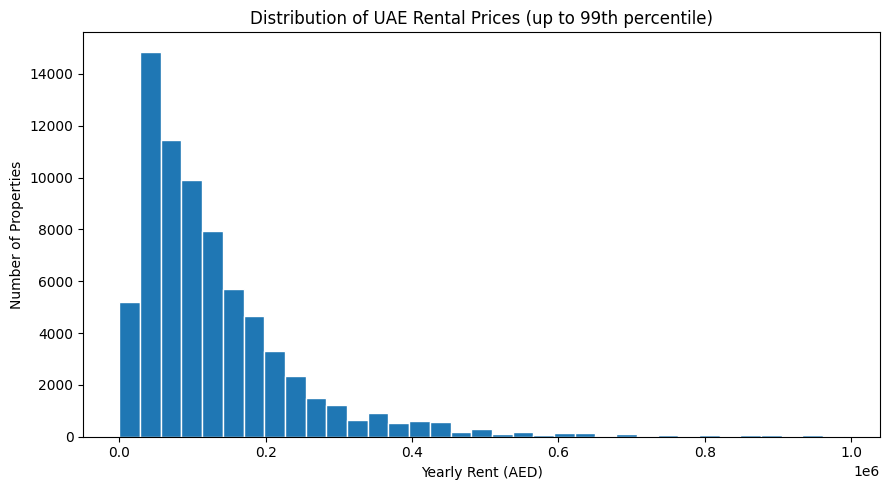

Median rent: AED 98,000
99th-percentile rent: AED 990,000
High outliers are kept in the dataset; this chart only limits the view.


In [9]:
rent_limit = chart_df['Rent'].quantile(0.99)
rent_for_chart = chart_df.loc[chart_df['Rent'].between(1, rent_limit), 'Rent']

plt.figure(figsize=(9, 5))
plt.hist(rent_for_chart, bins=35, edgecolor='white')
plt.title('Distribution of UAE Rental Prices (up to 99th percentile)')
plt.xlabel('Yearly Rent (AED)')
plt.ylabel('Number of Properties')
plt.tight_layout()
plt.show()

print(f'Median rent: AED {chart_df["Rent"].median():,.0f}')
print(f'99th-percentile rent: AED {rent_limit:,.0f}')
print('High outliers are kept in the dataset; this chart only limits the view.')

## 5. Chart 2 — Number of properties in each rent category

This helps us see how many properties are labelled **Low, Medium, and High**. `Rent_category` was kept unchanged for future classification.

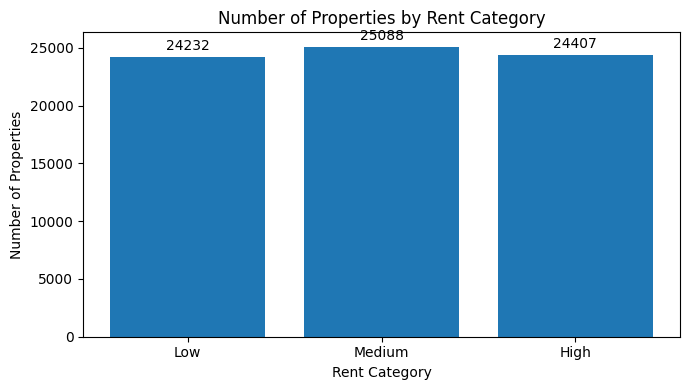

,Properties
Rent_category,
Low,24232
Medium,25088
High,24407


In [10]:
rent_counts = chart_df['Rent_category'].value_counts().reindex(['Low', 'Medium', 'High'], fill_value=0)

plt.figure(figsize=(7, 4))
bars = plt.bar(rent_counts.index, rent_counts.values)
plt.bar_label(bars, padding=3)
plt.title('Number of Properties by Rent Category')
plt.xlabel('Rent Category')
plt.ylabel('Number of Properties')
plt.tight_layout()
plt.show()

display(rent_counts.rename('Properties').to_frame())

## 6. Chart 3 — Median rent by city

We use the **median** rather than the mean because very expensive properties can strongly affect an average. This chart compares rental prices across UAE cities.

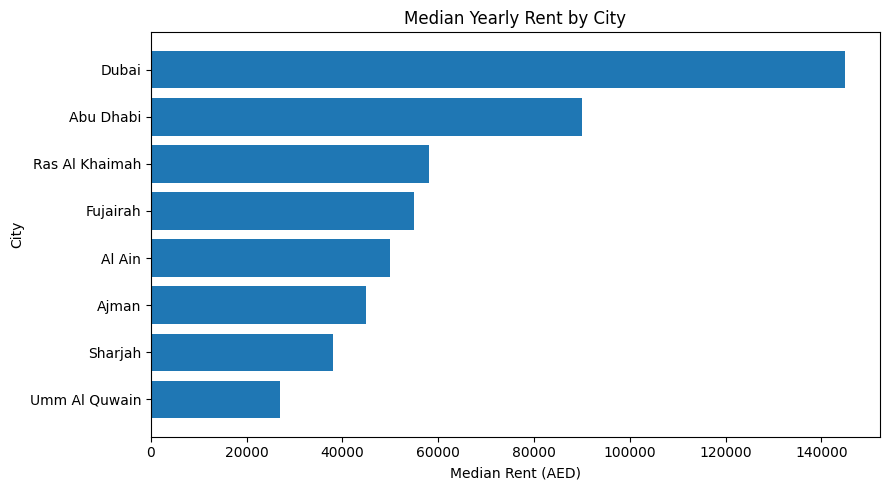

,Properties,Median Rent (AED)
City_label,,
Umm Al Quwain,65,27000.0
Sharjah,9515,37990.0
Ajman,4704,45000.0
Al Ain,1040,50000.0
Fujairah,27,55000.0
Ras Al Khaimah,816,58000.0
Abu Dhabi,23324,90000.0
Dubai,34236,145000.0


In [11]:
city_summary = chart_df.groupby('City_label')['Rent'].agg(['count','median']).sort_values('median')
city_summary = city_summary[city_summary.index != 'Not available']

plt.figure(figsize=(9, 5))
plt.barh(city_summary.index, city_summary['median'])
plt.title('Median Yearly Rent by City')
plt.xlabel('Median Rent (AED)')
plt.ylabel('City')
plt.tight_layout()
plt.show()

display(city_summary.rename(columns={'count':'Properties', 'median':'Median Rent (AED)'}).round(2))

## 7. Chart 4 — Median rent by property type

Compare the six most common property types. We select types by **number of listings**, not by price, so rare types do not dominate the comparison.

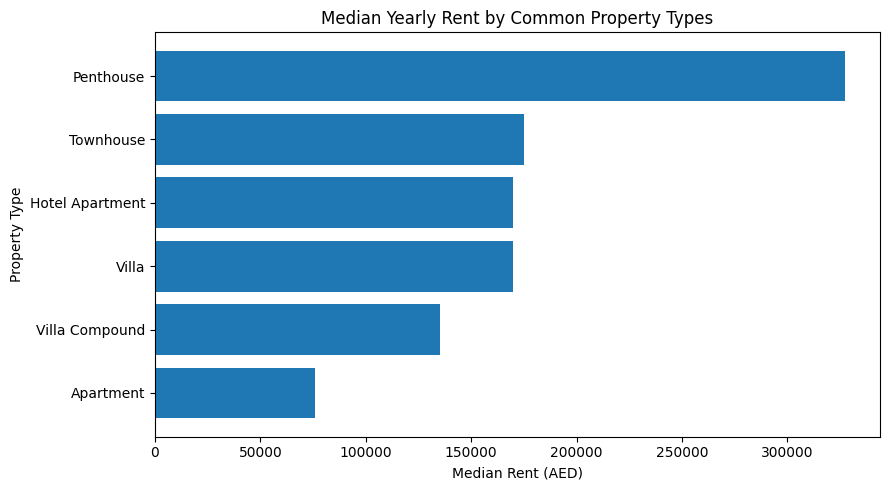

,Median Rent (AED)
Type_label,
Apartment,76000.0
Villa Compound,135000.0
Villa,170000.0
Hotel Apartment,170000.0
Townhouse,175000.0
Penthouse,327500.0


In [12]:
most_common_types = chart_df['Type_label'].value_counts().head(6).index
type_summary = (chart_df[chart_df['Type_label'].isin(most_common_types)]
                .groupby('Type_label')['Rent'].median().sort_values())

plt.figure(figsize=(9, 5))
plt.barh(type_summary.index, type_summary.values)
plt.title('Median Yearly Rent by Common Property Types')
plt.xlabel('Median Rent (AED)')
plt.ylabel('Property Type')
plt.tight_layout()
plt.show()

display(type_summary.rename('Median Rent (AED)').to_frame().round(2))

## 8. Chart 5 — Property size vs. rental price

A scatter plot helps us see whether larger properties are associated with higher rent. We use a reproducible sample and display values below the 99th percentile on each axis for readability.

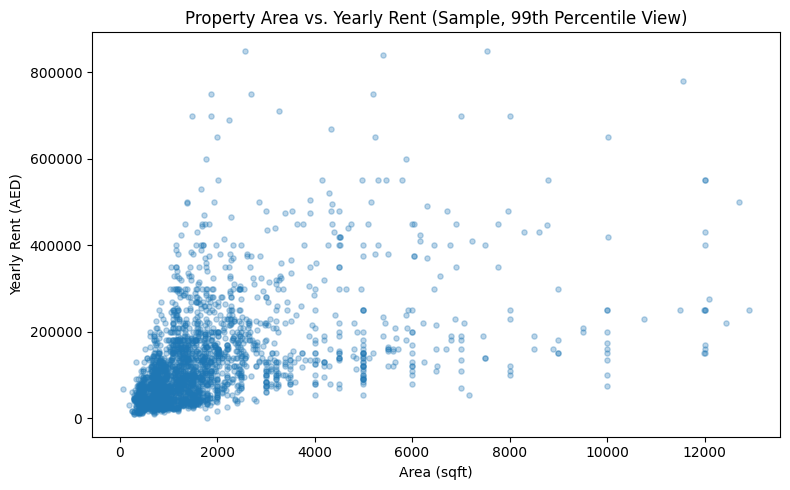

Properties used for scatter plot: 2500
This shows association, not proof that size alone causes rent differences.


In [13]:
area_limit = chart_df['Area_in_sqft'].quantile(0.99)
plot_data = chart_df[
    (chart_df['Area_in_sqft'] > 0) &
    (chart_df['Area_in_sqft'] <= area_limit) &
    (chart_df['Rent'] > 0) &
    (chart_df['Rent'] <= rent_limit)
]
plot_sample = plot_data.sample(n=min(2500, len(plot_data)), random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(plot_sample['Area_in_sqft'], plot_sample['Rent'], alpha=0.3, s=14)
plt.title('Property Area vs. Yearly Rent (Sample, 99th Percentile View)')
plt.xlabel('Area (sqft)')
plt.ylabel('Yearly Rent (AED)')
plt.tight_layout()
plt.show()

print('Properties used for scatter plot:', len(plot_sample))
print('This shows association, not proof that size alone causes rent differences.')

## 9. Chart 6 — Correlation between numerical attributes

Correlation values range from -1 to +1. They describe how numerical variables move together; **they do not prove causation**.

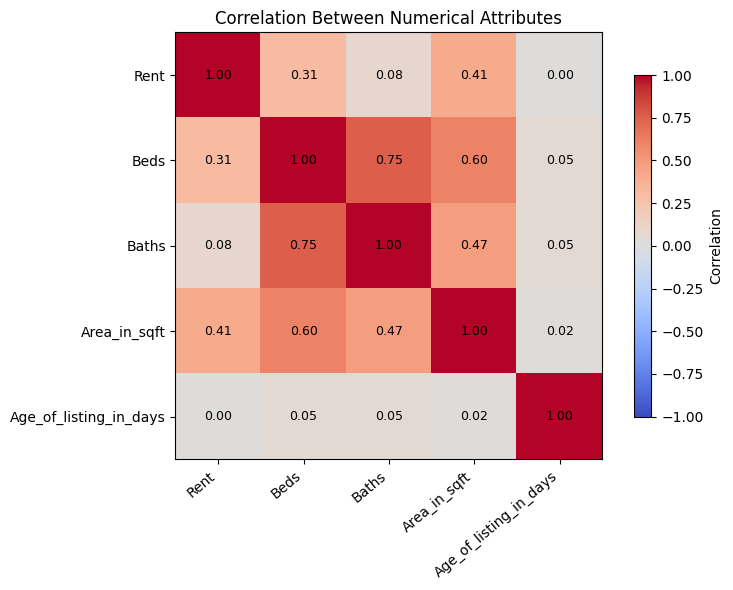

Correlation of each variable with Rent:


,Correlation with Rent
Rent,1.000
Area_in_sqft,0.406
Beds,0.310
Baths,0.081
Age_of_listing_in_days,0.001


In [14]:
corr_columns = ['Rent','Beds','Baths','Area_in_sqft','Age_of_listing_in_days']
corr_columns = [c for c in corr_columns if c in chart_df.columns]
corr = chart_df[corr_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr_columns)), corr_columns, rotation=40, ha='right')
ax.set_yticks(range(len(corr_columns)), corr_columns)
for i in range(len(corr_columns)):
    for j in range(len(corr_columns)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('Correlation Between Numerical Attributes')
fig.colorbar(image, ax=ax, shrink=0.8, label='Correlation')
fig.tight_layout()
plt.show()

print('Correlation of each variable with Rent:')
display(corr['Rent'].sort_values(ascending=False).round(3).to_frame('Correlation with Rent'))

## 10. Simple business findings

These facts are calculated from the cleaned dataset. Read the numbers in your own run and explain them **in your own words** in the report.

In [15]:
largest_city = chart_df['City_label'].value_counts().idxmax()
highest_median_city = city_summary['median'].idxmax()
common_type = chart_df['Type_label'].value_counts().idxmax()

print('Summary from this dataset:')
print(f'1. The dataset contains {len(chart_df):,} prepared property records.')
print(f'2. The typical (median) yearly rent is AED {chart_df["Rent"].median():,.0f}.')
print(f'3. The city with the most records is {largest_city}.')
print(f'4. The city with the highest median rent is {highest_median_city}.')
print(f'5. The most common property type is {common_type}.')
print('6. Extremely high rent and area values still need checking before modeling.')
print('7. Replaced coordinates may not represent exact property locations.')

Summary from this dataset:
1. The dataset contains 73,727 prepared property records.
2. The typical (median) yearly rent is AED 98,000.
3. The city with the most records is Dubai.
4. The city with the highest median rent is Dubai.
5. The most common property type is Apartment.
6. Extremely high rent and area values still need checking before modeling.
7. Replaced coordinates may not represent exact property locations.


## 11. Final check and next notebook

- We used the cleaned dataset from **Notebook 01** or RapidMiner.
- We produced summary statistics and six charts.
- We did not change the cleaned CSV or train models.
- **Next:** `03_feature_engineering.ipynb` to prepare useful model-specific features.

**Important:** `Rent_category` is derived from `Rent`. When later predicting `Rent_category`, do not use `Rent` as an input. When predicting `Rent`, do not use `Rent_category` as an input. This prevents target leakage.

**AI use:** Notebook code was prepared with ChatGPT assistance. Check the results and declare AI assistance in the GitHub README, following your instructor's instructions.